# DX799: Week 1: Linear Regression, Polynomial Terms & Interactions


## 1. Reproducibility and data sources


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

SEED=42
DATA_PATH=Path('movies.csv')
if not DATA_PATH.exists():
    DATA_PATH=Path('/mnt/data/movies.csv')
df_raw=pd.read_csv(DATA_PATH)
print('Raw shape:', df_raw.shape)
print('Columns:', df_raw.columns.tolist())

Raw shape: (18905, 23)
Columns: ['movie_id', 'title', 'original_title', 'release_date', 'release_year', 'runtime', 'genres', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'original_language', 'production_companies', 'production_countries', 'belongs_to_collection', 'adult', 'imdb_id', 'homepage', 'tagline', 'overview', 'runtime_missing']


## 2. Cleaning and exploratory data analysis

In [2]:
df=df_raw.drop_duplicates(subset=['movie_id']).copy()
df['release_date']=pd.to_datetime(df['release_date'], errors='coerce')
df['release_year']=pd.to_numeric(df['release_year'],errors='coerce')
for c in ['budget','revenue','runtime']:
    df[c]=pd.to_numeric(df[c],errors='coerce')
raw_count=len(df)
df=df.loc[(df.budget>0)&(df.revenue>0)&df.release_year.between(1980,2024)&df.runtime.between(40,240)&df.release_date.notna()].copy()
df['budget_m']=df.budget/1e6
df['revenue_m']=df.revenue/1e6
df['animation']=df.genres.fillna('').str.contains(r'(^|\|)Animation(\||$)',regex=True).astype(int)
df['release_month']=df.release_date.dt.month
# Genre indicators use strictly pre-release genre metadata.
for g in ['Action','Comedy','Drama','Horror']:
    df['genre_'+g.lower()]=df.genres.fillna('').str.contains(r'(^|\|)'+g+r'(\||$)',regex=True).astype(int)
# Reference month = January; 11 other months one-hot encoded.
for month in range(2,13):
    df[f'month_{month}']=(df.release_month==month).astype(int)
print(f'Unique input movie IDs: {raw_count:,}; final model sample: {len(df):,}')
print(f'Animated movies: {df.animation.sum():,}; other movies: {(1-df.animation).sum():,}')
print(df[['budget_m','revenue_m','runtime','release_year']].describe(percentiles=[.5,.9,.99]).round(2))

Unique input movie IDs: 18,905; final model sample: 7,079
Animated movies: 376; other movies: 6,703
       budget_m  revenue_m  runtime  release_year
count   7079.00    7079.00  7079.00       7079.00
mean      33.54      90.64   106.89       2004.89
std       43.70     181.95    17.75         11.39
min        0.00       0.00    56.00       1980.00
50%       19.00      26.81   104.00       2006.00
90%       80.00     233.96   130.00       2019.00
99%      200.00     921.46   165.00       2024.00
max      658.80    2923.71   229.00       2024.00


/tmp/ipykernel_1337/3991923873.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['animation']=df.genres.fillna('').str.contains(r'(^|\|)Animation(\||$)',regex=True).astype(int)
/tmp/ipykernel_1337/3991923873.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['genre_'+g.lower()]=df.genres.fillna('').str.contains(r'(^|\|)'+g+r'(\||$)',regex=True).astype(int)
/tmp/ipykernel_1337/3991923873.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['genre_'+g.lower()]=df.genres.fillna('').str.contains(r'(^|\|)'+g+r'(\||$)',regex=True).astype(int)
/tmp/ipykernel_1337/3991923873.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[

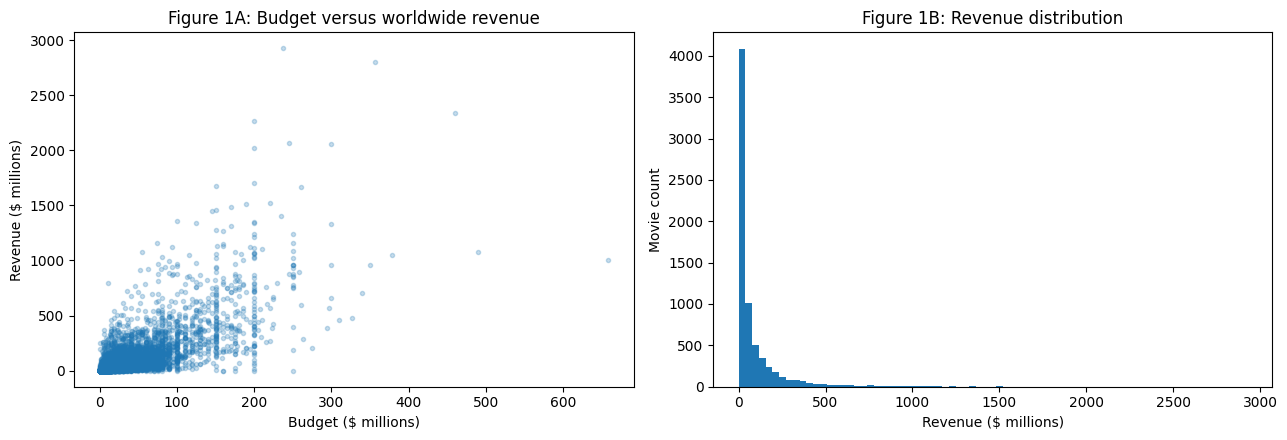

Pearson budget:revenue correlation: 0.726


In [3]:
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
ax[0].scatter(df.budget_m,df.revenue_m,s=9,alpha=.25)
ax[0].set(xlabel='Budget ($ millions)',ylabel='Revenue ($ millions)',title='Figure 1A: Budget versus worldwide revenue')
ax[1].hist(df.revenue_m,bins=75)
ax[1].set(xlabel='Revenue ($ millions)',ylabel='Movie count',title='Figure 1B: Revenue distribution')
plt.tight_layout();plt.show()
print('Pearson budget:revenue correlation:',round(df[['budget_m','revenue_m']].corr().iloc[0,1],3))

## 3. Baseline and feature design


In [4]:
base=['budget_m','runtime','release_year','animation','genre_action','genre_comedy','genre_drama','genre_horror']+[f'month_{i}' for i in range(2,13)]
# Fixed center from training ONLY (not computed from full dataset)
train_idx,test_idx=train_test_split(np.arange(len(df)),test_size=.2,random_state=SEED)
train=df.iloc[train_idx].copy();test=df.iloc[test_idx].copy()
budget_mean=train.budget_m.mean()
for part in [train,test]:
    part['budget_centered']=part.budget_m-budget_mean
    part['budget_centered_sq']=part.budget_centered**2
    part['budget_animation']=part.budget_centered*part.animation
features={
 'M0 Budget only':['budget_m'],
 'M1 Linear controls':base,
 'M2 + Budget squared':base+['budget_centered_sq'],
 'M3 + Interaction':base+['budget_centered_sq','budget_animation']
}
print('Train:',len(train),'Test:',len(test),'Mean training budget ($m):',round(budget_mean,3))

Train: 5663 Test: 1416 Mean training budget ($m): 33.486


## 4. Train/test metrics and five-fold cross-validation

In [5]:
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
rows=[]; models={}
for name,cols in features.items():
    est=LinearRegression()
    scoring={'r2':'r2','rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error'}
    out=cross_validate(est,train[cols],train.revenue_m,cv=cv,scoring=scoring,n_jobs=None)
    est.fit(train[cols],train.revenue_m);models[name]=est
    pred_train=est.predict(train[cols]);pred_test=est.predict(test[cols])
    rows.append({'model':name,'train_r2':r2_score(train.revenue_m,pred_train),
      'test_r2':r2_score(test.revenue_m,pred_test),'test_rmse_m':np.sqrt(mean_squared_error(test.revenue_m,pred_test)),
      'test_mae_m':mean_absolute_error(test.revenue_m,pred_test),
      'cv_r2_mean':out['test_r2'].mean(),'cv_r2_sd':out['test_r2'].std(),
      'cv_rmse_m':-out['test_rmse'].mean()})
results=pd.DataFrame(rows).set_index('model')
print(results.round(3).to_string())

                     train_r2  test_r2  test_rmse_m  test_mae_m  cv_r2_mean  cv_r2_sd  cv_rmse_m
model                                                                                           
M0 Budget only          0.532    0.497      114.421      62.187       0.527     0.015    127.538
M1 Linear controls      0.545    0.514      112.443      63.953       0.538     0.016    126.119
M2 + Budget squared     0.556    0.384      126.558      63.227       0.535     0.045    126.102
M3 + Interaction        0.558    0.389      126.028      62.976       0.536     0.042    125.954


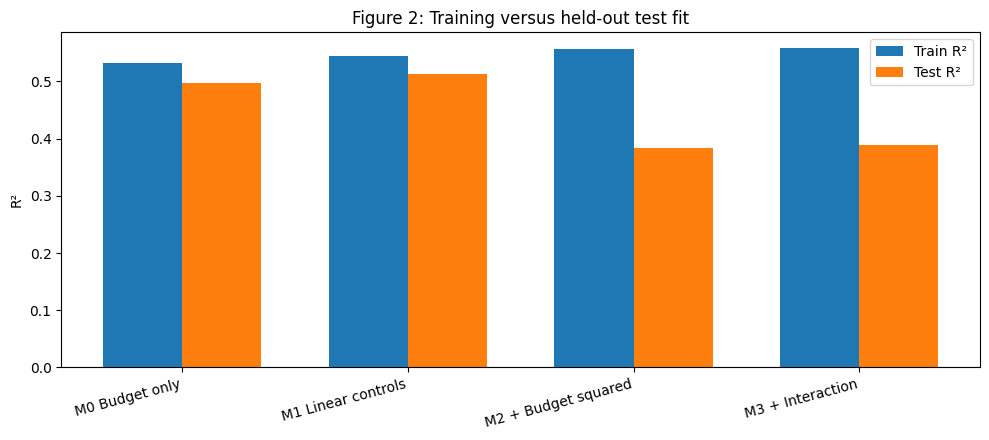

In [6]:
fig,ax=plt.subplots(figsize=(10,4.5))
x=np.arange(len(results))
w=.35
ax.bar(x-w/2,results.train_r2,width=w,label='Train R²')
ax.bar(x+w/2,results.test_r2,width=w,label='Test R²')
ax.set_xticks(x,results.index,rotation=15,ha='right')
ax.set(ylabel='R²',title='Figure 2: Training versus held-out test fit')
ax.axhline(0,linewidth=.8);ax.legend();plt.tight_layout();plt.show()

## 5. Multicollinearity: Pearson correlations and VIF

           feature  VIF
   budget_centered 3.29
budget_centered_sq 2.58
  budget_animation 1.53
         animation 1.49
           runtime 1.33
      release_year 1.06


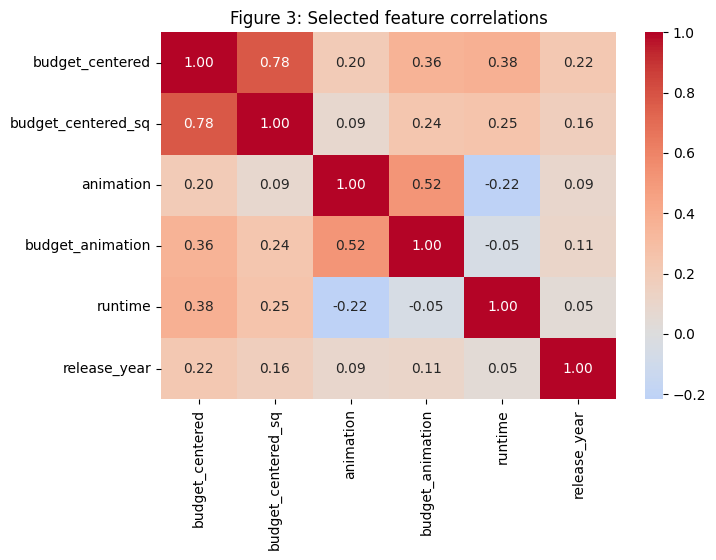

In [7]:
from statsmodels.tools.tools import add_constant
subcols=['budget_centered','budget_centered_sq','animation','budget_animation','runtime','release_year']
X_vif=add_constant(train[subcols],has_constant='add')
vifs=pd.DataFrame({'feature':subcols,'VIF':[variance_inflation_factor(X_vif.values,j+1) for j in range(len(subcols))]})
print(vifs.sort_values('VIF',ascending=False).round(2).to_string(index=False))
fig,ax=plt.subplots(figsize=(7.5,5.7))
sns.heatmap(train[subcols].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,ax=ax)
ax.set_title('Figure 3: Selected feature correlations')
plt.tight_layout();plt.show()

## 6. Polynomial effect and animation interaction

M3 coefficients (revenue and budget in $ millions):
budget_m               2.1748
runtime                1.1960
release_year           0.0596
animation             45.0559
genre_action          -3.2133
genre_comedy           6.6874
genre_drama          -24.7286
genre_horror           5.3934
month_2                3.1323
month_3                3.1469
month_4               17.2281
month_5               26.1571
month_6               37.7896
month_7               20.1213
month_8               -4.6632
month_9                2.4257
month_10               0.1256
month_11              10.8504
month_12              16.7290
budget_centered_sq     0.0047
budget_animation       0.6384
Intercept: -243.0184


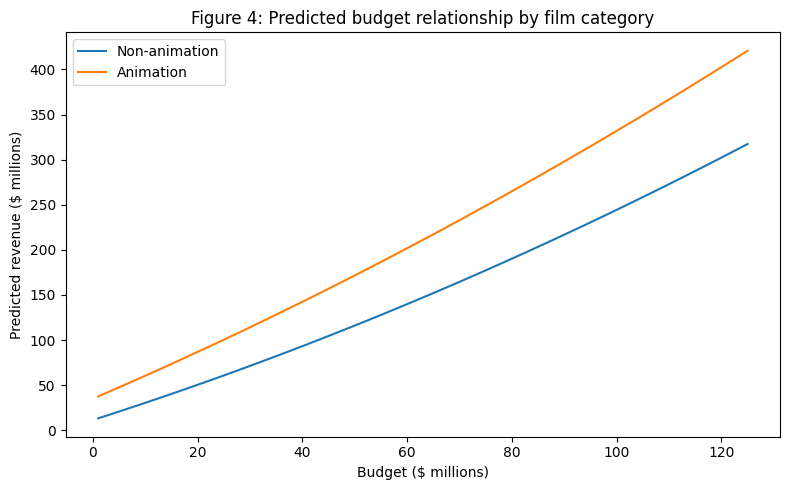

Plot budget range (5th:95th pct training): 1.0 125.0


In [8]:
best=models['M3 + Interaction']
print('M3 coefficients (revenue and budget in $ millions):')
print(pd.Series(best.coef_,index=features['M3 + Interaction']).round(4).to_string())
print('Intercept:',round(best.intercept_,4))
q_low,q_high=train.budget_m.quantile([.05,.95]);grid=np.linspace(q_low,q_high,80)
fig,ax=plt.subplots(figsize=(8,5))
for animated,label in [(0,'Non-animation'),(1,'Animation')]:
    frame=pd.DataFrame([train[base].mean()]*len(grid))
    frame['budget_m']=grid
    frame['animation']=animated
    frame['budget_centered_sq']=(grid-budget_mean)**2
    frame['budget_animation']=(grid-budget_mean)*animated
    pred=best.predict(frame[features['M3 + Interaction']])
    ax.plot(grid,pred,label=label)
ax.set(xlabel='Budget ($ millions)',ylabel='Predicted revenue ($ millions)',title='Figure 4: Predicted budget relationship by film category')
ax.legend();plt.tight_layout();plt.show()
print('Plot budget range (5th:95th pct training):',round(q_low,2),round(q_high,2))

## 7. Prediction residuals and extreme values

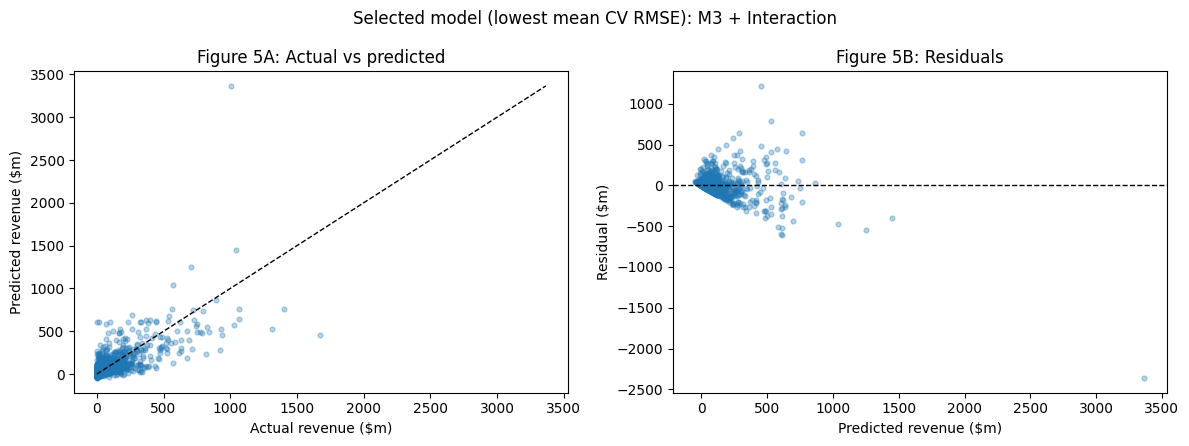

In [9]:
chosen=min(results.index,key=lambda nm:results.loc[nm,'cv_rmse_m'])
model=models[chosen]
yhat=model.predict(test[features[chosen]])
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
ax[0].scatter(test.revenue_m,yhat,alpha=.32,s=12)
lim=max(test.revenue_m.max(),yhat.max());ax[0].plot([0,lim],[0,lim],'k--',linewidth=1)
ax[0].set(xlabel='Actual revenue ($m)',ylabel='Predicted revenue ($m)',title='Figure 5A: Actual vs predicted')
ax[1].scatter(yhat,test.revenue_m-yhat,alpha=.32,s=12)
ax[1].axhline(0,color='black',linestyle='--',linewidth=1)
ax[1].set(xlabel='Predicted revenue ($m)',ylabel='Residual ($m)',title='Figure 5B: Residuals')
plt.suptitle('Selected model (lowest mean CV RMSE): '+chosen)
plt.tight_layout();plt.show()